In [85]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

In [6]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()
x_train, x_test = x_train / 255.0, x_test / 255.0


In [55]:
print(x_train.shape, y_train.shape, x_test.shape, y_test.shape)

(50000, 32, 32, 3) (50000, 1) (10000, 32, 32, 3) (10000, 1)


[1]
[4]


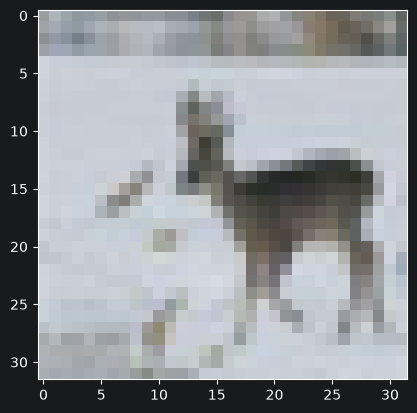

In [56]:
plt.imshow(x_train[20])
print(y_train[4])
print(y_train[20])

In [91]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(32,32,3)),
    tf.keras.layers.Conv2D(32, (3, 3), activation='relu', padding='same', input_shape=(32, 32, 3)),
    tf.keras.layers.MaxPooling2D(pool_size=(2, 2)),

    tf.keras.layers.Conv2D(16, (3, 3), activation='relu', padding='same', input_shape=(32, 32, 3)),
    tf.keras.layers.MaxPooling2D(pool_size=(2, 2)),

    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(16, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])


In [65]:
model.summary()

Model: "sequential_20"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_7 (Conv2D)               │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 16, 16, 16)     │         4,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 8, 8, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_40 (Dense)                │ (None, 16)             │        16,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_41 (Dense)                │ (None, 10)             │           170 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 22,090 (86.29 KB)

 Trainable params: 22,090 (86.29 KB)

 Non-trainable params: 0 (0.00 B)

In [66]:
x_train_f = x_train.reshape(50000, 32*32*3)
model.fit(x_train, y_train, epochs=10)

Epoch 1/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 14s 8ms/step - accuracy: 0.4112 - loss: 1.6250
Epoch 2/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 16s 10ms/step - accuracy: 0.5526 - loss: 1.2631
Epoch 3/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 16s 10ms/step - accuracy: 0.6042 - loss: 1.1316
Epoch 4/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 16s 10ms/step - accuracy: 0.6323 - loss: 1.0528
Epoch 5/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 16s 10ms/step - accuracy: 0.6502 - loss: 1.0063
Epoch 6/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 16s 10ms/step - accuracy: 0.6630 - loss: 0.9654
Epoch 7/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 17s 11ms/step - accuracy: 0.6713 - loss: 0.9399
Epoch 8/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 16s 10ms/step - accuracy: 0.6800 - loss: 0.9165
Epoch 9/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 16s 10ms/step - accuracy: 0.6892 - loss: 0.8920
Epoch 10/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 16s 10ms/step - accuracy: 0.6925 - loss: 0.8827


In [79]:
import os
import cv2

In [86]:
IMG_SIZE = 150
train_dir = "data/train"
test_dir = "data/test"
categories = ["NORMAL", "PNEUMONIA"]

def load_data(data_dir):
    X, y = [], []
    for category in categories:
        path = os.path.join(data_dir, category)
        label = categories.index(category)  # Assign labels (0 for normal, 1 for pneumonia)

        for img_name in os.listdir(path):
            img_path = os.path.join(path, img_name)
            img = cv2.imread(img_path)  # Read image
            img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))  # Resize to (150x150)
            img = img / 255.0  # Normalize pixel values (0-1)
            X.append(img)
            y.append(label)

    return np.array(X), np.array(y)


In [87]:
X_train, y_train = load_data(train_dir)
X_test, y_test = load_data(test_dir)
print(X_train.shape, y_train.shape, X_test.shape, y_test.shape)


(148, 150, 150, 3) (148,) (40, 150, 150, 3) (40,)


In [93]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(150,150,3)),
    tf.keras.layers.Conv2D(32, (3, 3), activation='relu', padding='same', input_shape=(32, 32, 3)),
    tf.keras.layers.MaxPooling2D(pool_size=(2, 2)),

    tf.keras.layers.Conv2D(16, (3, 3), activation='relu', padding='same', input_shape=(32, 32, 3)),
    tf.keras.layers.MaxPooling2D(pool_size=(2, 2)),

    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(16, activation='relu'),
    tf.keras.layers.Dense(2, activation='softmax')
])
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])
x_train_f = x_train.reshape(50000, 32 * 32 * 3)

In [95]:
model.fit(X_train, y_train, epochs = 5 )

Epoch 1/5
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 116ms/step - accuracy: 0.9257 - loss: 0.1706
Epoch 2/5
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 119ms/step - accuracy: 0.9392 - loss: 0.1726
Epoch 3/5
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 115ms/step - accuracy: 0.9324 - loss: 0.1758
Epoch 4/5
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 128ms/step - accuracy: 0.9730 - loss: 0.1105
Epoch 5/5
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 120ms/step - accuracy: 0.9730 - loss: 0.0940


In [96]:
model.evaluate(X_test, y_test)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.9500 - loss: 0.1056 


[0.10561732947826385, 0.949999988079071]

In [97]:
model.save("pneumonia_classifier_cv2.h5")


In [99]:
def predict_image(img_path, model):
    img = cv2.imread(img_path)
    img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
    img = img / 255.0
    img = np.expand_dims(img, axis=0)  # Expand dimensions for model input
    prediction = model.predict(img)
    class_index = np.argmax(prediction)
    return "Pneumonia" if class_index == 1 else "Normal"


img_path = "data/test/NORMAL/NORMAL2-IM-0072-0001.jpeg  "
print("Prediction:", predict_image(img_path, model))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
Prediction: Normal
